In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
)

In [2]:
PROJECT_DIR = Path(
    "/Users/kakulrajput/Documents/Image_Detection"
)

PREDICTIONS_PATH = (
    PROJECT_DIR / "reports" / "validation_predictions.csv"
)

predictions_df = pd.read_csv(PREDICTIONS_PATH)

print("Prediction file exists:", PREDICTIONS_PATH.exists())
print("Number of predictions:", len(predictions_df))

display(predictions_df.sample(20))

Prediction file exists: True
Number of predictions: 771


,path,true_label,predicted_label,unsafe_probability,true_class,predicted_class,correct
273,/Users/kakulrajput/Documents/Image_Detection/d...,0,1,0.736145,safe,unsafe,False
4,/Users/kakulrajput/Documents/Image_Detection/d...,0,0,0.138735,safe,safe,True
550,/Users/kakulrajput/Documents/Image_Detection/d...,1,1,0.938193,unsafe,unsafe,True
65,/Users/kakulrajput/Documents/Image_Detection/d...,0,0,0.006012,safe,safe,True
225,/Users/kakulrajput/Documents/Image_Detection/d...,0,0,0.003399,safe,safe,True
352,/Users/kakulrajput/Documents/Image_Detection/d...,0,1,0.911836,safe,unsafe,False
277,/Users/kakulrajput/Documents/Image_Detection/d...,0,0,0.215683,safe,safe,True
152,/Users/kakulrajput/Documents/Image_Detection/d...,0,1,0.791978,safe,unsafe,False
496,/Users/kakulrajput/Documents/Image_Detection/d...,1,1,0.996671,unsafe,unsafe,True
680,/Users/kakulrajput/Documents/Image_Detection/d...,1,1,0.766005,unsafe,unsafe,True


In [3]:
required_columns = {
    "true_label",
    "predicted_label",
    "unsafe_probability",
}

missing_columns = required_columns - set(predictions_df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

assert predictions_df["true_label"].isin([0, 1]).all()

assert predictions_df["unsafe_probability"].between(0, 1).all()

assert predictions_df["unsafe_probability"].notna().all()

print("Prediction data verified.")

Prediction data verified.


In [4]:
y_true = predictions_df["true_label"].to_numpy()

unsafe_probabilities = predictions_df[
    "unsafe_probability"
].to_numpy()

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:
    y_pred = (
        unsafe_probabilities >= threshold
    ).astype(int)

    results.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))

,threshold,accuracy,precision,recall,f1
0,0.10,0.7380,0.6805,0.9378,0.7887
1,0.15,0.7717,0.7233,0.9104,0.8062
2,0.20,0.7860,0.7453,0.8955,0.8136
3,0.25,0.8054,0.7739,0.8856,0.8260
4,0.30,0.8236,0.8023,0.8781,0.8385
5,0.35,0.8340,0.8231,0.8682,0.8450
6,0.40,0.8353,0.8313,0.8582,0.8446
7,0.45,0.8431,0.8539,0.8433,0.8486
8,0.50,0.8392,0.8582,0.8284,0.8430
9,0.55,0.8314,0.8617,0.8060,0.8329


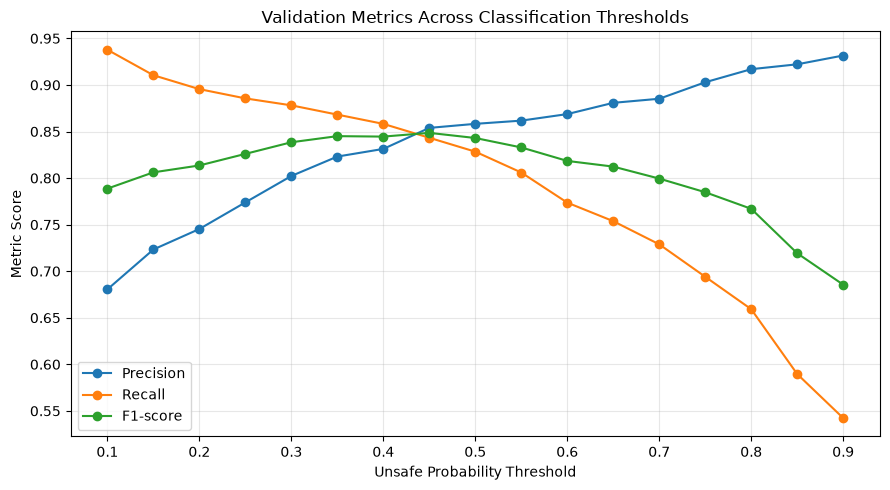

In [5]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision",
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall",
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    marker="o",
    label="F1-score",
)

plt.xlabel("Unsafe Probability Threshold")
plt.ylabel("Metric Score")
plt.title("Validation Metrics Across Classification Thresholds")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
threshold = 0.50

y_pred = (
    unsafe_probabilities >= threshold
).astype(int)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
)

print("Threshold:", threshold)
print(cm)

Threshold: 0.5
[[314  55]
 [ 69 333]]


In [7]:
best_index = threshold_results["f1"].idxmax()

best_row = threshold_results.loc[best_index]

print("Best threshold by validation F1:")
print(best_row)

Best threshold by validation F1:
threshold    0.450000
accuracy     0.843061
precision    0.853904
recall       0.843284
f1           0.848561
Name: 7, dtype: float64
